In [1]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import pearsonr, spearmanr

np.random.seed(1)

city = "Київ"
monthly_temp = [-4, -3, 2, 9, 15, 19, 21, 20, 14, 8, 2, -2]

months = [
    "Січ", "Лют", "Бер", "Кві", "Тра", "Чер",
    "Лип", "Сер", "Вер", "Жов", "Лис", "Гру"
]

rows = []

for month, temp in zip(months, monthly_temp):
    heating_days = np.clip(
        18 - temp + np.random.normal(0, 1.5), 0, 30
    )
    heating_days = round(heating_days)

    cost = 0.15 * heating_days + np.random.normal(0, 1.0)
    cost = round(max(cost, 0), 1)

    rows.append({
        "місто": city,
        "місяць": month,
        "температура": temp,
        "опалювальні_дні": heating_days,
        "витрати_на_опалення": cost,
    })

climate = pd.DataFrame(rows)

print("Варіант: 1")
print("Місто:", city)
print("Розмір набору:", climate.shape)
display(climate)


Варіант: 1
Місто: Київ
Розмір набору: (12, 5)


,місто,місяць,температура,опалювальні_дні,витрати_на_опалення
0,Київ,Січ,-4,24,3.0
1,Київ,Лют,-3,20,1.9
2,Київ,Бер,2,17,0.2
3,Київ,Кві,9,12,1.0
4,Київ,Тра,15,3,0.2
5,Київ,Чер,19,1,0.0
6,Київ,Лип,21,0,0.0
7,Київ,Сер,20,0,0.0
8,Київ,Вер,14,4,0.0
9,Київ,Жов,8,10,2.1


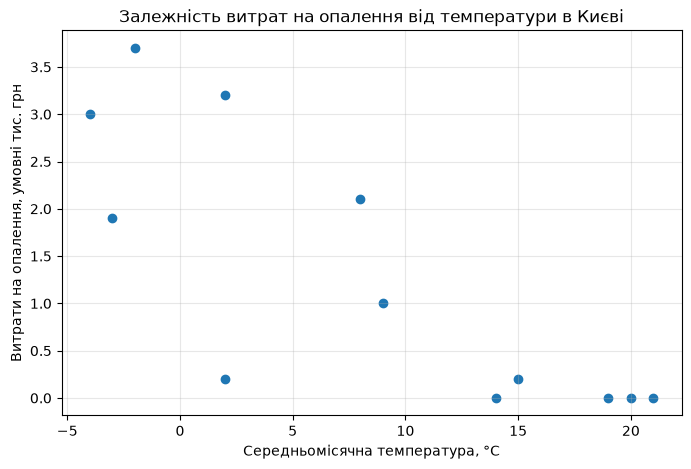

In [2]:

# Діаграма розсіювання: температура та витрати на опалення
plt.figure(figsize=(8, 5))

plt.scatter(
    climate["температура"],
    climate["витрати_на_опалення"]
)

plt.xlabel("Середньомісячна температура, °C")
plt.ylabel("Витрати на опалення, умовні тис. грн")
plt.title("Залежність витрат на опалення від температури в Києві")
plt.grid(True, alpha=0.3)
plt.show()



### Завдання 1. Діаграма розсіювання

На діаграмі розсіювання показано залежність витрат на опалення від середньомісячної температури в Києві. Очікується негативний зв'язок: за нижчої температури опалення зазвичай потрібне довше, а витрати зростають. Форма хмари точок має загалом спадний напрямок, хоча окремі точки можуть відхилятися через випадковий шум у формулі генерації. Явні викиди потрібно оцінювати за фактичним виглядом графіка.

In [3]:

# Кореляція температури та витрат на опалення
x = climate["температура"]
y = climate["витрати_на_опалення"]

pearson_result = pearsonr(x, y)
spearman_result = spearmanr(x, y)

print(f"Пірсон: r = {pearson_result.statistic:.4f}")
print(f"p-value Пірсона = {pearson_result.pvalue:.6f}")

print(f"\nСпірмен: rho = {spearman_result.statistic:.4f}")
print(f"p-value Спірмена = {spearman_result.pvalue:.6f}")

# 95%-й довірчий інтервал коефіцієнта Пірсона
ci = pearson_result.confidence_interval(confidence_level=0.95)

print(
    f"\n95%-й довірчий інтервал Пірсона: "
    f"[{ci.low:.4f}; {ci.high:.4f}]"
)

alpha = 0.05

if pearson_result.pvalue < alpha:
    print("\nПірсон: відхиляємо H₀ — кореляція статистично значуща.")
else:
    print("\nПірсон: недостатньо підстав відхилити H₀.")

if spearman_result.pvalue < alpha:
    print("Спірмен: відхиляємо H₀ — кореляція статистично значуща.")
else:
    print("Спірмен: недостатньо підстав відхилити H₀.")


Пірсон: r = -0.8065
p-value Пірсона = 0.001528

Спірмен: rho = -0.8269
p-value Спірмена = 0.000908

95%-й довірчий інтервал Пірсона: [-0.9436; -0.4330]

Пірсон: відхиляємо H₀ — кореляція статистично значуща.
Спірмен: відхиляємо H₀ — кореляція статистично значуща.



### Завдання 2. Коефіцієнти Пірсона і Спірмена

Коефіцієнт Пірсона вимірює силу та напрямок лінійного зв'язку, а коефіцієнт Спірмена оцінює монотонний зв'язок за рангами. Якщо їхні значення близькі, це може свідчити про те, що лінійний зв'язок добре описує загальну залежність. Відмінності можуть виникати через випадковий шум, нелінійність або вплив окремих спостережень.

Нульова гіпотеза H₀ для кожного тесту стверджує, що відповідна кореляція в генеральній сукупності дорівнює нулю. Якщо p-value менше за 0,05, H₀ відхиляємо; інакше недостатньо підстав її відхилити.

95%-й довірчий інтервал Пірсона показує діапазон значень, сумісних із даними та використаним методом оцінювання на 95%-му рівні довіри. Якщо інтервал не містить нуля, це узгоджується зі статистично значущою кореляцією на рівні 0,05.


In [4]:

# Три числові змінні
numeric_data = climate[
    ["температура", "опалювальні_дні", "витрати_на_опалення"]
]

# Кореляційна матриця Пірсона
corr_pearson = numeric_data.corr(method="pearson")

print("Кореляційна матриця Пірсона:")
display(corr_pearson.round(3))

# Кореляційна матриця Спірмена
corr_spearman = numeric_data.corr(method="spearman")

print("Кореляційна матриця Спірмена:")
display(corr_spearman.round(3))

# Порівняння сили зв'язків
pairs = [
    ("температура", "опалювальні_дні"),
    ("температура", "витрати_на_опалення"),
    ("опалювальні_дні", "витрати_на_опалення"),
]

for a, b in pairs:
    print(
        f"{a} — {b}: "
        f"Пірсон = {corr_pearson.loc[a, b]:.3f}, "
        f"Спірмен = {corr_spearman.loc[a, b]:.3f}"
    )


Кореляційна матриця Пірсона:


,температура,опалювальні_дні,витрати_на_опалення
температура,1.000,-0.987,-0.806
опалювальні_дні,-0.987,1.000,0.787
витрати_на_опалення,-0.806,0.787,1.000


Кореляційна матриця Спірмена:


,температура,опалювальні_дні,витрати_на_опалення
температура,1.000,-0.982,-0.827
опалювальні_дні,-0.982,1.000,0.822
витрати_на_опалення,-0.827,0.822,1.000


температура — опалювальні_дні: Пірсон = -0.987, Спірмен = -0.982
температура — витрати_на_опалення: Пірсон = -0.806, Спірмен = -0.827
опалювальні_дні — витрати_на_опалення: Пірсон = 0.787, Спірмен = 0.822



### Завдання 3. Кореляційна матриця

Кореляційна матриця Пірсона показує силу лінійного зв'язку між трьома числовими змінними, а матриця Спірмена — силу монотонного зв'язку за рангами. Найсильніша пара визначається за найбільшим абсолютним значенням коефіцієнта поза головною діагоналлю, а найслабша — за найменшим.

Очікується, що температура матиме від'ємний зв'язок з опалювальними днями та витратами, оскільки холодніші місяці потребують більшого опалення. Опалювальні дні та витрати мають тенденцію до позитивного зв'язку, адже витрати обчислюються на основі кількості опалювальних днів із додаванням випадкового шуму.

Порівняння двох матриць дає змогу побачити, чи змінюються оцінки сили зв'язку залежно від методу. Остаточний висновок про найсильнішу та найслабшу пару робиться за отриманими числовими значеннями.



### Завдання 4. Кореляція і причинність

У цьому наборі даних зв'язок між температурою та витратами на опалення закладений у формулі генерації. Спочатку кількість опалювальних днів обчислюється на основі температури, а потім витрати визначаються за кількістю опалювальних днів із додаванням випадкового шуму.

Отже, у створеній моделі температура впливає на витрати опосередковано — через кількість опалювальних днів. Проте в реальному житті витрати залежать також від тарифів, площі житла, утеплення будівлі та інших чинників. Тому кореляція сама по собі не доводить причинність: необхідно враховувати спосіб отримання даних та інші можливі причини зв'язку.

In [5]:

# Додаємо аномальне спостереження:
# висока температура, але дуже великі витрати через аварію
anomaly = pd.DataFrame([{
    "місто": city,
    "місяць": "Аварія",
    "температура": 21,
    "опалювальні_дні": 0,
    "витрати_на_опалення": 50.0,
}])

climate_anomaly = pd.concat(
    [climate, anomaly],
    ignore_index=True
)

# Початкові коефіцієнти
pearson_before = pearsonr(
    climate["температура"],
    climate["витрати_на_опалення"]
).statistic

spearman_before = spearmanr(
    climate["температура"],
    climate["витрати_на_опалення"]
).statistic

# Коефіцієнти після додавання викиду
pearson_after = pearsonr(
    climate_anomaly["температура"],
    climate_anomaly["витрати_на_опалення"]
).statistic

spearman_after = spearmanr(
    climate_anomaly["температура"],
    climate_anomaly["витрати_на_опалення"]
).statistic

print(f"Пірсон до викиду: {pearson_before:.4f}")
print(f"Пірсон після викиду: {pearson_after:.4f}")
print(f"Зміна Пірсона: {abs(pearson_after - pearson_before):.4f}")

print(f"\nСпірмен до викиду: {spearman_before:.4f}")
print(f"Спірмен після викиду: {spearman_after:.4f}")
print(f"Зміна Спірмена: {abs(spearman_after - spearman_before):.4f}")

display(climate_anomaly.tail(3))


Пірсон до викиду: -0.8065
Пірсон після викиду: 0.2867
Зміна Пірсона: 1.0932

Спірмен до викиду: -0.8269
Спірмен після викиду: -0.4588
Зміна Спірмена: 0.3681


,місто,місяць,температура,опалювальні_дні,витрати_на_опалення
10,Київ,Лис,2,14,3.2
11,Київ,Гру,-2,21,3.7
12,Київ,Аварія,21,0,50.0



### Завдання 5. Вплив викиду на кореляцію

До початкового набору даних було додано аномальне спостереження з дуже великими витратами на опалення за високої температури. Після цього повторно обчислено коефіцієнти кореляції Пірсона та Спірмена.

Коефіцієнт Пірсона чутливий до викидів, оскільки використовує фактичні числові значення. Коефіцієнт Спірмена ґрунтується на рангах, тому зазвичай менш чутливий до величини екстремального значення. Порівняння коефіцієнтів до та після додавання аномального спостереження дає змогу оцінити вплив викиду на силу й напрямок зв'язку.

Результати обчислень показують, наскільки змінилися обидва коефіцієнти після додавання аномального спостереження.



## Відповіді на контрольні запитання

**1. Чому коефіцієнт Пірсона ділиться на добуток стандартних відхилень і чому він перебуває в межах [-1; 1]?**

Ділення коваріації на добуток стандартних відхилень нормує її, усуває одиниці вимірювання та дає змогу порівнювати силу лінійного зв'язку між різними змінними. За нерівністю Коші — Буняковського абсолютне значення коефіцієнта не перевищує 1. Значення +1 означає ідеальний позитивний лінійний зв'язок, −1 — ідеальний негативний, а 0 — відсутність лінійного зв'язку.

**2. Чому коефіцієнт Спірмена обчислюється на рангах і як це робить його стійкішим до викидів?**

Спірмен замінює початкові значення їхніми рангами, тобто порядковими номерами. Тому величина екстремального значення не впливає на коефіцієнт пропорційно до свого числового розміру. Це робить Спірмена зазвичай менш чутливим до викидів, ніж Пірсона, хоча вплив аномальних спостережень усе одно можливий.

**3. Наведіть приклад сильного зв'язку, коли коефіцієнт Пірсона r приблизно дорівнює нулю.**

Прикладом є залежність Y = X², якщо значення X симетрично розподілені навколо нуля. Між X та Y існує чітка нелінійна U-подібна залежність, але лінійна кореляція Пірсона може дорівнювати нулю. Це пояснюється тим, що Пірсон вимірює саме лінійний зв'язок.

**4. Чому сильна кореляція не доводить, що одна змінна спричиняє зміни іншої?**

Кореляція описує статистичний зв'язок між змінними, але не встановлює причинно-наслідковий зв'язок. Кореляція може виникати через вплив третього чинника, зворотний вплив або особливості вибірки. Для підтвердження причинності потрібні додаткові докази та відповідний дизайн дослідження.
